In [1]:
# pip install h5py numpy

In [6]:
import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# BRIAN'S PATH #
path = r"C:\Users\Brian\Desktop\School\ME4452 - Machine Learning for Engineers\Project\frog_11-36_12-43_train_val.h5"

# BEN'S PATH #
# path = r""

with h5py.File(path, "r") as f:
    print(list(f.keys()))
    for name in f.keys():
        item = f[name]
        print(name, item.shape, item.dtype)

['circle_idx', 'circle_num', 'circles', 'scans', 'split', 'timestamps']
circle_idx (120396,) int32
circle_num (120396,) int32
circles (473005, 6) float32
scans (120396, 720) float32
split (120396,) uint8
timestamps (120396,) float64


#### Dataset Overview:
Every scan is 180 degrees (front of robot) and has 720 points. Each scan has a certain number of circles representing annotated people, shown in circle_num. The information about these people (x, y, distance, etc) is stored in circles and is accessed using circle_idx. \
\
Example: We are looking at scan[10]. circle_num[10] gives the number of annotated people within scan[10] for all 720 measurements. circle_idx[10] gives the starting point in circles[] for the information about each annotated person. So, for scan[10], all the annotated people can be found withing circles[circle_idx[10]] to circles[circle_idx[10]+circle_num[10]].

##### NOTE:
The following dataframe is just for ease of use when viewing data. When interacting with ENTIRE dataset (.h5 file), DO NOT convert to dataframe.

In [21]:
with h5py.File(path, "r") as f:
    # Each row is a scan; each column is one LiDAR measurement. Comes from "scans".
    scan_df = pd.DataFrame(
        f["scans"][:10],
        columns=[f"beam_{i}" for i in range(f["scans"].shape[1])]
    )

    # One row per scan, with its number of annotated people. 
    counts = f["circle_num"][:2000]
    count_df = pd.DataFrame({
        "scan_idx": np.arange(2000),
        "person_count": counts
    })

    # One row per annotated person in those scans.
    rows = []
    for scan_idx in range(2000):
        start = int(f["circle_idx"][scan_idx])
        count = int(f["circle_num"][scan_idx])

        for person in f["circles"][start : start + count]:
            rows.append([scan_idx, *person])

annotation_df = pd.DataFrame(
    rows,
    columns=["scan_idx", "x_m", "y_m", "radius_m",
             "distance_m", "angle_rad", "half_angle_rad"]
)

display(scan_df)
display(count_df)
display(annotation_df)

,beam_0,beam_1,beam_2,beam_3,beam_4,beam_5,beam_6,beam_7,beam_8,beam_9,...,beam_710,beam_711,beam_712,beam_713,beam_714,beam_715,beam_716,beam_717,beam_718,beam_719
0,5.582,2.474,2.473,2.471,2.455,2.471,2.471,5.591,5.599,5.591,...,1.626,1.626,1.621,1.621,1.602,1.614,1.614,1.619,1.614,1.614
1,5.553,2.461,2.451,2.451,2.451,2.451,2.472,5.594,5.601,5.623,...,1.630,1.625,1.620,1.625,1.620,1.609,1.620,1.623,1.609,1.617
2,5.580,2.498,2.489,2.489,2.459,2.489,2.511,5.624,5.638,5.638,...,1.630,1.630,1.630,1.629,1.627,1.627,1.627,1.621,1.627,1.621
3,5.576,2.470,2.470,2.470,2.464,2.474,2.500,5.599,5.599,5.600,...,1.625,1.622,1.622,1.622,1.622,1.622,1.617,1.617,1.617,1.617
4,5.584,2.482,2.476,2.474,2.474,2.474,2.476,5.610,5.616,5.622,...,1.613,1.613,1.612,1.612,1.610,1.612,1.614,1.623,1.623,1.623
5,5.549,2.478,2.471,2.457,2.446,2.446,2.446,5.629,5.629,5.629,...,1.624,1.628,1.624,1.624,1.623,1.623,1.623,1.624,1.624,1.624
6,5.604,2.484,2.473,2.462,2.434,2.462,2.462,5.593,5.601,5.608,...,1.612,1.602,1.602,1.613,1.613,1.616,1.619,1.619,1.614,1.619
7,5.602,2.496,2.467,2.467,2.460,2.460,2.515,5.587,5.597,5.597,...,1.620,1.620,1.617,1.619,1.619,1.614,1.606,1.606,1.606,1.618
8,5.590,2.458,2.458,2.448,2.448,2.448,2.528,5.626,5.626,5.615,...,1.617,1.617,1.614,1.614,1.614,1.623,1.627,1.629,1.636,1.629
9,5.554,2.483,2.476,2.467,2.455,2.455,2.455,5.603,5.614,5.614,...,1.629,1.629,1.610,1.609,1.609,1.607,1.607,1.607,1.607,1.610


,scan_idx,person_count
0,0,2
1,1,2
2,2,2
3,3,2
4,4,2
...,...,...
1995,1995,3
1996,1996,3
1997,1997,3
1998,1998,3


,scan_idx,x_m,y_m,radius_m,distance_m,angle_rad,half_angle_rad
0,0,2.795095,0.826195,0.4,2.914645,0.287404,0.136386
1,0,2.033462,1.267302,0.4,2.396043,0.557321,0.165416
2,1,2.794747,0.826274,0.4,2.914334,0.287463,0.136400
3,1,2.028309,1.270123,0.4,2.393167,0.559460,0.165612
4,2,2.802647,0.828468,0.4,2.922531,0.287417,0.136022
...,...,...,...,...,...,...,...
4287,1998,1.409238,-5.122587,0.4,5.312895,-1.302335,0.075147
4288,1998,0.561009,-2.937624,0.4,2.990713,-1.382095,0.132958
4289,1999,2.349526,-5.406525,0.4,5.894979,-1.160846,0.067750
4290,1999,1.393973,-5.153996,0.4,5.339179,-1.306652,0.074778


In [ ]:
with h5py.File(path, "r") as f:
    if "scans" in f:
        scans = f["scans"]
        print(scans[0, :])       # all 720 measurements in the first scan

# Scans go right -> left (counterclockwise)

[ 5.582  2.474  2.473  2.471  2.455  2.471  2.471  5.591  5.599  5.591
  5.563  5.559  5.553  2.498  2.498  2.498  2.506  5.567  5.618  8.701
  8.701  7.434 61.    61.    61.     2.47   2.47   2.487  2.499  2.499
  2.769  2.874  2.874  2.874 61.    61.    61.     2.443  2.474  2.474
  2.452  2.452 61.    61.    61.    61.    61.    61.     5.316  5.316
  2.514  2.513  2.513  2.514  5.504  5.555  5.555  5.556  9.197  9.197
  9.167  2.539  2.539  2.539  2.539  2.533  2.539 61.    61.    61.
 61.    61.    34.511 34.511  2.562  2.561  2.561  2.561  7.845  7.908
  7.887  7.887  7.887 61.     2.574  2.576  2.576  2.578  2.578 10.283
 10.283 10.23  10.189 10.17  10.145 10.114  2.644  2.644  2.644 10.113
 10.167 10.251 10.251  6.199  6.175  6.175  2.709  2.709  2.709  5.943
  5.943  5.943  6.016  6.016  5.956  2.759  2.759  2.741  2.741 61.
 61.    61.    61.     7.596  7.617  7.596  2.878  2.815  2.801  2.801
 61.    61.    19.822 20.08  20.08   2.887  2.867  2.848 61.    61.
 61.    61.    

,people_per_scan,number_of_scans,percent_of_scans
0,1,13926,11.566829
1,2,22084,18.342802
2,3,23545,19.556298
3,4,20089,16.685770
4,5,14503,12.046081
5,6,10901,9.054288
6,7,6394,5.310808
7,8,4189,3.479351
8,9,2368,1.966843
9,10,946,0.785740


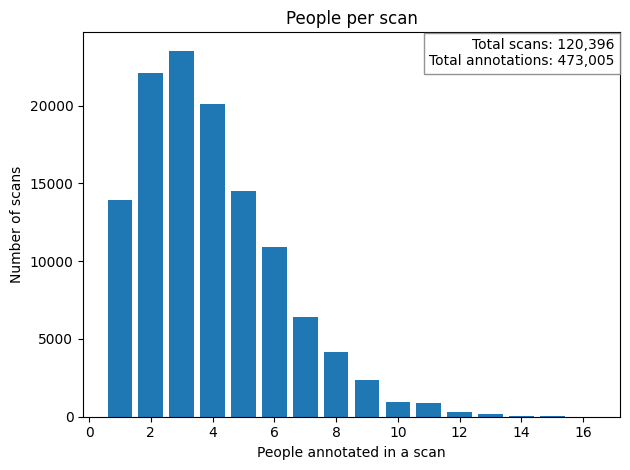

In [19]:
with h5py.File(path, "r") as f:
    counts = f["circle_num"][:]
    circles = f["circles"][:]

# Summary: scan count and percentage for each number of people
summary_df = (
    pd.Series(counts, name="people_per_scan")
    .value_counts()
    .sort_index()
    .rename_axis("people_per_scan")
    .reset_index(name="number_of_scans")
)
summary_df["percent_of_scans"] = (
    100 * summary_df["number_of_scans"] / len(counts)
)

display(summary_df)

fig, axes = plt.subplots()

plt.bar(summary_df["people_per_scan"], summary_df["number_of_scans"])
axes.set(
    xlabel="People annotated in a scan",
    ylabel="Number of scans",
    title="People per scan"
)

axes.text(
    0.99, 0.985,
    f"Total scans: {len(counts):,}\n"
    f"Total annotations: {len(circles):,}",
    transform=axes.transAxes,
    ha="right",
    va="top",
    bbox=dict(facecolor="white", alpha=0.85, edgecolor="gray")
)

plt.tight_layout()
plt.show()

#### NOTE:
This is a filtered dataset, every scan has at least one annotated person. This could pose an issue if our model ends up detecting an abundance of false positives. Also no way of validating false positives in empty environment.

,count,mean,std,min,25%,median,75%,max,units
x_m,473005.0,3.482,2.424,0.004,1.471,3.031,5.144,9.990,m
y_m,473005.0,0.259,2.478,-9.814,-1.213,0.431,1.707,9.750,m
radius_m,473005.0,0.399,0.026,0.200,0.400,0.400,0.400,1.000,m
distance_m,473005.0,4.337,2.324,0.304,2.395,3.974,6.006,9.998,m
angle_rad,473005.0,0.081,0.729,-1.569,-0.374,0.107,0.574,1.564,rad
angular_radius_rad,473005.0,0.132,0.095,0.020,0.066,0.100,0.165,0.921,rad


,x_m,y_m,radius_m,distance_m,angle_rad,angular_radius_rad
0,9.833333,0.208333,0.4,9.835540,0.021183,0.040646
1,9.812575,0.171619,0.4,9.814076,0.017488,0.040735
2,9.769976,0.106811,0.4,9.770560,0.010932,0.040916
3,9.740016,0.127944,0.4,9.740856,0.013135,0.041041
4,9.707411,0.127255,0.4,9.708244,0.013108,0.041179


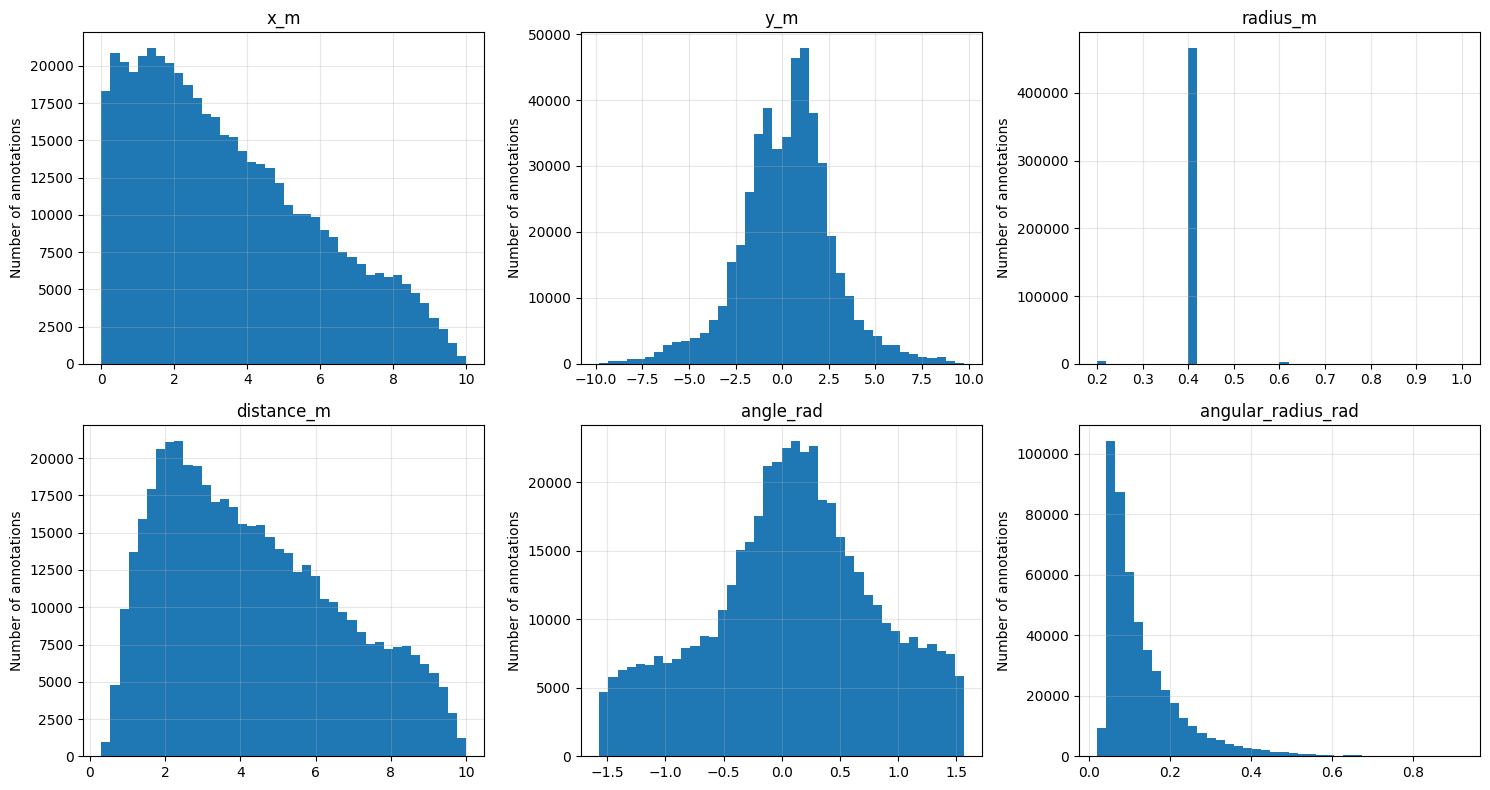

In [28]:
with h5py.File(path, "r") as f:
    circles = f["circles"][:]

attributes_df = pd.DataFrame(
    circles,
    columns=[
        "x_m",
        "y_m",
        "radius_m",
        "distance_m",
        "angle_rad",
        "angular_radius_rad",
    ],
)

# Tabular distribution summary
summary_df = attributes_df.describe(
    percentiles=[0.25, 0.50, 0.75]
).T.rename(columns={"50%": "median"})

summary_df["units"] = ["m", "m", "m", "m", "rad", "rad"]
display(summary_df.round(3))

display(attributes_df.head())

# Plot all six distributions
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for column, ax in zip(attributes_df.columns, axes.flat):
    ax.hist(attributes_df[column], bins=40)
    ax.set_title(column)
    ax.set_ylabel("Number of annotations")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

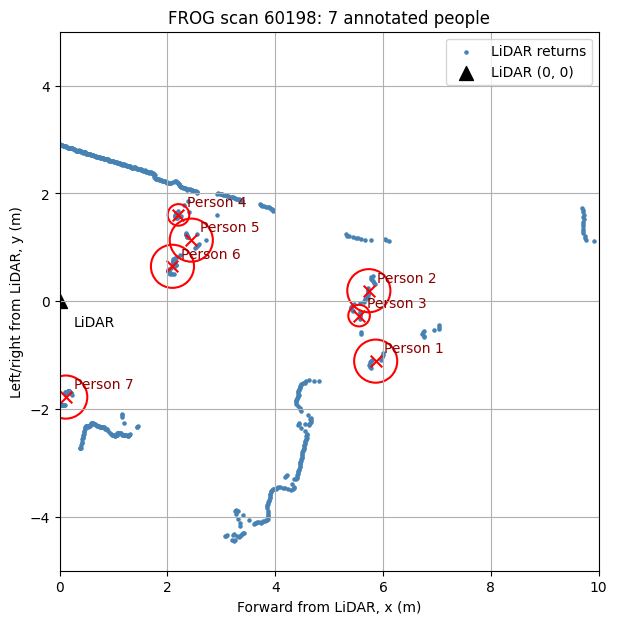

In [32]:
from matplotlib.patches import Circle

with h5py.File(path, "r") as f:
    counts = f["circle_num"][:]

    # Choose a scan that has at least one person
    candidates = np.flatnonzero(counts > 0)
    scan_idx = int(candidates[len(candidates) // 2])

    ranges = f["scans"][scan_idx]
    start = int(f["circle_idx"][scan_idx])
    people = f["circles"][start : start + int(counts[scan_idx])]

# Convert the 180° scan from ranges to x-y points
angles = np.linspace(-np.pi / 2, np.pi / 2, len(ranges))
scan_x = ranges * np.cos(angles)
scan_y = ranges * np.sin(angles)

fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(scan_x, scan_y, s=5, color="steelblue", label="LiDAR returns")

# LiDAR is the origin
ax.scatter(0, 0, marker="^", s=100, color="black", label="LiDAR (0, 0)")
ax.annotate("LiDAR", (0, 0), xytext=(10, -18), textcoords="offset points")

# Each row is [x, y, radius, distance, angle, angular_radius]
for person_num, person in enumerate(people, start=1):
    x, y, radius = person[:3]
    ax.add_patch(Circle((x, y), radius, fill=False, color="red", linewidth=1.5))
    ax.scatter(x, y, marker="x", s=70, color="red")
    ax.annotate(
        f"Person {person_num}",
        (x, y),
        xytext=(6, 6),
        textcoords="offset points",
        color="darkred"
    )

ax.set_xlim(0, 10)
ax.set_ylim(-5, 5)
ax.set_aspect("equal")
ax.set_xlabel("Forward from LiDAR, x (m)")
ax.set_ylabel("Left/right from LiDAR, y (m)")
ax.set_title(f"FROG scan {scan_idx}: {len(people)} annotated people")
ax.grid(True)
ax.legend()
plt.show()